Лабораторная работа №5. квантовые сумматоры. Алгоритм Гровера.

In [3]:
!pip install -q qiskit qiskit-aer pylatexenc matplotlib numpy

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from math import pi, floor, sin, asin, sqrt
from collections import Counter
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector, Operator
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error

sim = AerSimulator()
sv_sim = AerSimulator(method='statevector')

Задание 1. Полные сумматоры и цепочка переноса.

1.1 Сумматор A=1, B=0, X=1

In [5]:
print("ЗАДАНИЕ 1. Квантовые сумматоры")

# Полный сумматор A=1, B=0, X=1
qc = QuantumCircuit(5, 2)
qc.x(0);
qc.x(2)

qc.cx(0,3);
qc.cx(1,3);
qc.cx(2,3)

qc.ccx(0,1,4);
qc.ccx(1,2,4);
qc.ccx(0,2,4)

qc.measure(3,0);
qc.measure(4,1)

res = sim.run(qc, shots=1024).result().get_counts()
print("1.1 A=1,B=0,X=1 ->", res, "(ожидалось '10': S=0, C=1)")

def full_adder_5q(a,b,x):
    qc = QuantumCircuit(5,2)
    if a: qc.x(0)
    if b: qc.x(1)
    if x: qc.x(2)
    qc.cx(0,3);
    qc.cx(1,3);
    qc.cx(2,3)

    qc.ccx(0,1,4);
    qc.ccx(1,2,4);
    qc.ccx(0,2,4)

    qc.measure(3,0);
    qc.measure(4,1)
    return qc

def half_adder(qc,a,b,s,c):
    qc.cx(a,s);
    qc.cx(b,s);
    qc.ccx(a,b,c)

def full_adder_ha(a,b,x):
    qc = QuantumCircuit(8,2)
    if a: qc.x(0)
    if b: qc.x(1)
    if x: qc.x(2)
    half_adder(qc,0,1,3,4)
    half_adder(qc,3,2,5,6)
    qc.x(4);
    qc.x(6);
    qc.ccx(4,6,7);
    qc.x(7);
    qc.x(4);
    qc.x(6)
    qc.measure(5,0);
    qc.measure(7,1)
    return qc

truth = [(0,0,0,0,0),(0,0,1,1,0),(0,1,0,1,0),(0,1,1,0,1),(1,0,0,1,0),(1,0,1,0,1),(1,1,0,0,1),(1,1,1,1,1)]

print("\n1.2. Полный сумматор: проверка всех входов")
print(f"{'A':>2}{'B':>2}{'X':>2} | {'S_ожид':>7}{'C_ожид':>7} | "f"{'S_5q':>5}{'C_5q':>5} | {'S_HA':>5}{'C_HA':>5} | статус")
all_ok = True
for a,b,x,es,ec in truth:
    c5 = sim.run(full_adder_5q(a,b,x), shots=512).result().get_counts()
    got5 = list(c5.keys())[0]; gc5,gs5 = int(got5[0]), int(got5[1])
    ch = sim.run(full_adder_ha(a,b,x), shots=512).result().get_counts()
    goth = list(ch.keys())[0]; gch,gsh = int(goth[0]), int(goth[1])
    ok = (gs5,gc5)==(es,ec) and (gsh,gch)==(es,ec)
    all_ok = all_ok and ok
    print(f"{a:>2}{b:>2}{x:>2} | {es:>7}{ec:>7} | "f"{gs5:>5}{gc5:>5} | {gsh:>5}{gch:>5} | {'OK' if ok else 'FAIL'}")
assert all_ok
print("1.2 5q и HA: все 8 входов OK")

qc5 = full_adder_5q(0,0,0);
qc5.remove_final_measurements()
qha = full_adder_ha(0,0,0);
qha.remove_final_measurements()
print(f"1.3 5q:  qubits={qc5.num_qubits}, CX={qc5.count_ops().get('cx',0)}, "f"CCX={qc5.count_ops().get('ccx',0)}, depth={qc5.depth()}")
print(f"1.3 HA:  qubits={qha.num_qubits}, CX={qha.count_ops().get('cx',0)}, "f"CCX={qha.count_ops().get('ccx',0)}, depth={qha.depth()}")

print("\n 1.3. Сравнение реализаций полного сумматора")
print(f"{'реализация':>12} | {'qubits':>6} | {'CX':>3} | {'CCX':>3} | {'depth':>5}")
for nm, qc in [("5q (direct)", qc5), ("2×HA + OR", qha)]:
    ops = qc.count_ops()
    print(f"{nm:>12} | {qc.num_qubits:>6} | {ops.get('cx',0):>3} | "f"{ops.get('ccx',0):>3} | {qc.depth():>5}")

def ripple_adder(n):
    qc = QuantumCircuit(4*n+1)
    for i in range(n):
        ai, bi, si = i, n+i, 2*n+i
        cin, cout = 3*n+i, 3*n+i+1
        qc.cx(ai,si);
        qc.cx(bi,si);
        qc.cx(cin,si)
        qc.ccx(ai,bi,cout);
        qc.ccx(bi,cin,cout);
        qc.ccx(ai,cin,cout)
    return qc

def test_ripple(n):
    gates = ripple_adder(n)
    for a in range(2**n):
        for b in range(2**n):
            qc = QuantumCircuit(gates.num_qubits, n+1)
            for i in range(n):
                if (a>>i)&1: qc.x(i)
                if (b>>i)&1: qc.x(n+i)
            qc.compose(gates, inplace=True)
            qc.measure(list(range(2*n,3*n))+[4*n], list(range(n+1)))
            c = sim.run(qc, shots=64).result().get_counts()
            assert int(list(c.keys())[0], 2) == a+b

print("\n1.4. Ripple-carry сумматор")
print(f"{'n':>2} | {'пар':>4} | {'qubits':>6} | {'CX':>4} | {'CCX':>4} | {'depth':>5}")
for n in (2,3,4):
    test_ripple(n)
    qc = ripple_adder(n); ops = qc.count_ops()
    print(f"{n:>2} | {4**n:>4} | {qc.num_qubits:>6} | {ops.get('cx',0):>4} | "f"{ops.get('ccx',0):>4} | {qc.depth():>5}")
print("1.4 все пары OK для n=2,3,4")

ЗАДАНИЕ 1. Квантовые сумматоры
1.1 A=1,B=0,X=1 -> {'10': 1024} (ожидалось '10': S=0, C=1)

1.2. Полный сумматор: проверка всех входов
 A B X |  S_ожид C_ожид |  S_5q C_5q |  S_HA C_HA | статус
 0 0 0 |       0      0 |     0    0 |     0    0 | OK
 0 0 1 |       1      0 |     1    0 |     1    0 | OK
 0 1 0 |       1      0 |     1    0 |     1    0 | OK
 0 1 1 |       0      1 |     0    1 |     0    1 | OK
 1 0 0 |       1      0 |     1    0 |     1    0 | OK
 1 0 1 |       0      1 |     0    1 |     0    1 | OK
 1 1 0 |       0      1 |     0    1 |     0    1 | OK
 1 1 1 |       1      1 |     1    1 |     1    1 | OK
1.2 5q и HA: все 8 входов OK
1.3 5q:  qubits=5, CX=3, CCX=3, depth=5
1.3 HA:  qubits=8, CX=4, CCX=3, depth=8

 1.3. Сравнение реализаций полного сумматора
  реализация | qubits |  CX | CCX | depth
 5q (direct) |      5 |   3 |   3 |     5
   2×HA + OR |      8 |   4 |   3 |     8

1.4. Ripple-carry сумматор
 n |  пар | qubits |   CX |  CCX | depth
 2 |   16 |      

Задание 2. Вариант 1 - F(A, B, C, D) = (A NOR B) ⊕ (C NAND D)

In [6]:
print("ЗАДАНИЕ 2. F(A,B,C,D) = (A NOR B) ⊕ (C NAND D)")

def F_classical(A,B,C,D):
    return int((not (A or B)) ^ (not (C and D)))

def gate_OR(qc,a,b,out):
    qc.x(a);
    qc.x(b);
    qc.ccx(a,b,out);
    qc.x(out);
    qc.x(a);
    qc.x(b)

def gate_NOT(qc, a, out):
    qc.x(out)
    qc.cx(a, out)

def gate_AND(qc, a, b, out):
    qc.ccx(a, b, out)

def gate_OR(qc, a, b, out):
    qc.x(a); qc.x(b)
    qc.ccx(a, b, out)
    qc.x(out)
    qc.x(a); qc.x(b)

def gate_XOR(qc, a, b, out):
    qc.cx(a, out)
    qc.cx(b, out)

def gate_NAND(qc, a, b, out):
    qc.ccx(a, b, out)
    qc.x(out)

def gate_NOR(qc, a, b, out):
    gate_OR(qc, a, b, out)
    qc.x(out)

def gate_MAJ(qc, a, b, c, out):
    qc.ccx(a, b, out)
    qc.ccx(a, c, out)
    qc.ccx(b, c, out)

def F_quantum_basic():
    qc = QuantumCircuit(7, 1)
    # q5 = NOR(A,B)
    gate_NOR(qc, 0, 1, 5)
    # q6 = NAND(C,D)
    gate_NAND(qc, 2, 3, 6)
    # F = q5 ⊕ q6
    gate_XOR(qc, 5, 6, 4)
    # uncompute
    gate_NAND(qc, 2, 3, 6)
    gate_NOR(qc, 0, 1, 5)
    qc.measure(4, 0)
    return qc

def F_quantum_opt():
    qc = QuantumCircuit(7, 1)
    gate_OR(qc, 0, 1, 5)  # q5 = A∨B
    gate_AND(qc, 2, 3, 6) # q6 = C∧D
    gate_XOR(qc, 5, 6, 4) # F = q5 ⊕ q6)
    gate_AND(qc, 2, 3, 6) # uncompute
    gate_OR(qc, 0, 1, 5) # uncompute
    qc.measure(4, 0)
    return qc

def _run_F(builder, A,B,C,D):
    b0 = builder(); b0.remove_final_measurements(inplace=True)
    qc = QuantumCircuit(b0.num_qubits)
    if A: qc.x(0)
    if B: qc.x(1)
    if C: qc.x(2)
    if D: qc.x(3)
    qc.compose(b0, inplace=True)
    sv = Statevector.from_instruction(qc)
    idx = int(np.argmax(sv.probabilities()))
    aux_ok = all(((idx>>q)&1)==0 for q in range(5, qc.num_qubits))
    return (idx>>4)&1, aux_ok

print("\n2.х. F(A,B,C,D) = (A NOR B) ⊕ (C NAND D)")
print(f"{'A':>1}{'B':>1}{'C':>1}{'D':>1} | {'F_класс':>7} | {'F_basic':>7} | "f"{'F_opt':>5} | anc | статус")
ok_all = True
for bits in range(16):
    A=(bits>>3)&1; B=(bits>>2)&1; C=(bits>>1)&1; D=bits&1
    exp = F_classical(A,B,C,D)
    fb, ab = _run_F(F_quantum_basic, A,B,C,D)
    fo, ao = _run_F(F_quantum_opt, A,B,C,D)
    ok = (fb==exp) and (fo==exp) and ab and ao
    ok_all = ok_all and ok
    print(f"{A:>1}{B:>1}{C:>1}{D:>1} | {exp:>7} | {fb:>7} | "f"{fo:>5} | {'0' if (ab and ao) else '!0'} | {'OK' if ok else 'FAIL'}")
assert ok_all
print("2.x basic и opt: 16/16 correct, анциллы чистые")

qc_b = F_quantum_basic();
qc_b.remove_final_measurements()

qc_o = F_quantum_opt();
qc_o.remove_final_measurements()
for nm, qc in [("basic", qc_b), ("opt", qc_o)]:
    ops = qc.count_ops()
    print(f"2.y {nm}: qubits={qc.num_qubits}, CX={ops.get('cx',0)}, "f"CCX={ops.get('ccx',0)}, depth={qc.depth()}")

print("\nТаблица 2.y. Сравнение реализаций F")
print(f"{'версия':>6} | {'qubits':>6} | {'CX':>3} | {'CCX':>3} | {'depth':>5}")
for nm, qc in [("basic", qc_b), ("opt", qc_o)]:
    ops = qc.count_ops()
    print(f"{nm:>6} | {qc.num_qubits:>6} | {ops.get('cx',0):>3} | "f"{ops.get('ccx',0):>3} | {qc.depth():>5}")

ЗАДАНИЕ 2. F(A,B,C,D) = (A NOR B) ⊕ (C NAND D)

2.х. F(A,B,C,D) = (A NOR B) ⊕ (C NAND D)
ABCD | F_класс | F_basic | F_opt | anc | статус
0000 |       0 |       0 |     0 | 0 | OK
0001 |       0 |       0 |     0 | 0 | OK
0010 |       0 |       0 |     0 | 0 | OK
0011 |       1 |       1 |     1 | 0 | OK
0100 |       1 |       1 |     1 | 0 | OK
0101 |       1 |       1 |     1 | 0 | OK
0110 |       1 |       1 |     1 | 0 | OK
0111 |       0 |       0 |     0 | 0 | OK
1000 |       1 |       1 |     1 | 0 | OK
1001 |       1 |       1 |     1 | 0 | OK
1010 |       1 |       1 |     1 | 0 | OK
1011 |       0 |       0 |     0 | 0 | OK
1100 |       1 |       1 |     1 | 0 | OK
1101 |       1 |       1 |     1 | 0 | OK
1110 |       1 |       1 |     1 | 0 | OK
1111 |       0 |       0 |     0 | 0 | OK
2.x basic и opt: 16/16 correct, анциллы чистые
2.y basic: qubits=7, CX=2, CCX=4, depth=8
2.y opt: qubits=7, CX=2, CCX=4, depth=6

Таблица 2.y. Сравнение реализаций F
версия | qubits |  CX | C

Задание 3. Работа оптимизированной схемы с шумом.

ЗАДАНИЕ 3. Шум с оптимизированной схемой
3 p2=0.000: basic=0.989 (CX=26) | opt=0.990 (CX=26)
3 p2=0.001: basic=0.982 (CX=26) | opt=0.985 (CX=26)
3 p2=0.005: basic=0.968 (CX=26) | opt=0.966 (CX=26)
3 p2=0.010: basic=0.942 (CX=26) | opt=0.946 (CX=26)
3 p2=0.020: basic=0.896 (CX=26) | opt=0.901 (CX=26)

Доля правильных ответов при шуме
    p2 |   basic ( CX) |     opt ( CX)
 0.000 |   0.989 ( 26) |   0.990 ( 26)
 0.001 |   0.982 ( 26) |   0.985 ( 26)
 0.005 |   0.968 ( 26) |   0.966 ( 26)
 0.010 |   0.942 ( 26) |   0.946 ( 26)
 0.020 |   0.896 ( 26) |   0.901 ( 26)


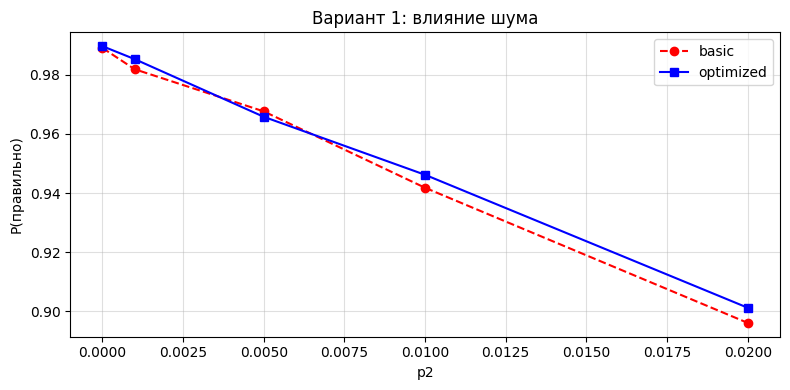

In [7]:
print("ЗАДАНИЕ 3. Шум с оптимизированной схемой")

def eval_noise(builder, p2, shots=512):
    nm = NoiseModel()
    nm.add_all_qubit_quantum_error(depolarizing_error(0.001,1), ['rz','sx','x'])
    if p2 > 0:
        nm.add_all_qubit_quantum_error(depolarizing_error(p2,2), ['cx'])
    tqc = transpile(builder(), basis_gates=['rz','sx','x','cx'], optimization_level=1)
    avg = 0.0
    for bits in range(16):
        A=(bits>>3)&1; B=(bits>>2)&1; C=(bits>>1)&1; D=bits&1
        exp = F_classical(A,B,C,D)
        qc = QuantumCircuit(tqc.num_qubits, 1)
        if A: qc.x(0)
        if B: qc.x(1)
        if C: qc.x(2)
        if D: qc.x(3)
        qc.compose(tqc, inplace=True)
        c = sim.run(qc, shots=shots, noise_model=nm).result().get_counts()
        avg += c.get(str(exp),0)/shots
    return avg/16, tqc.count_ops().get('cx',0)

p2_list = [0, 0.001, 0.005, 0.01, 0.02]
rb, ro = [], []
for p2 in p2_list:
    pb, cxb = eval_noise(F_quantum_basic, p2)
    po, cxo = eval_noise(F_quantum_opt, p2)
    rb.append(pb); ro.append(po)
    print(f"3 p2={p2:.3f}: basic={pb:.3f} (CX={cxb}) | opt={po:.3f} (CX={cxo})")

print("\nДоля правильных ответов при шуме")
print(f"{'p2':>6} | {'basic':>7} ({'CX':>3}) | {'opt':>7} ({'CX':>3})")
for i, p2 in enumerate(p2_list):
    _, cxb = eval_noise(F_quantum_basic, p2)
    _, cxo = eval_noise(F_quantum_opt, p2)
    print(f"{p2:>6.3f} | {rb[i]:>7.3f} ({cxb:>3}) | {ro[i]:>7.3f} ({cxo:>3})")

plt.figure(figsize=(8,4))
plt.plot(p2_list, rb, 'r--o', label='basic')
plt.plot(p2_list, ro, 'b-s', label='optimized')
plt.xlabel('p2'); plt.ylabel('P(правильно)')
plt.title('Вариант 1: влияние шума'); plt.legend(); plt.grid(alpha=0.4)
plt.tight_layout(); plt.show()

Задание 4. Оракул, диффузор и алгоритм Гровера.

In [8]:
print("ЗАДАНИЕ 4. Оракул, диффузор и алгоритм Гровера")

def build_oracle(n, marked):
    """U_w|x> = -|x> при x==marked; Qiskit: q0 — младший бит."""
    qc = QuantumCircuit(n)
    for i, bit in enumerate(reversed(marked)):
        if bit == '0':
            qc.x(i)
    qc.h(n-1); qc.mcx(list(range(n-1)), n-1); qc.h(n-1)
    for i, bit in enumerate(reversed(marked)):
        if bit == '0':
            qc.x(i)
    return qc

def build_diffuser(n):
    qc = QuantumCircuit(n)
    qc.h(range(n)); qc.x(range(n))
    qc.h(n-1); qc.mcx(list(range(n-1)), n-1); qc.h(n-1)
    qc.x(range(n)); qc.h(range(n))
    return qc

def build_grover(n, marked, k):
    """k итераций: H^n, затем k раз (оракул + диффузор)."""
    qc = QuantumCircuit(n)
    qc.h(range(n))
    for _ in range(k):
        qc.compose(build_oracle(n, marked), inplace=True)
        qc.compose(build_diffuser(n), inplace=True)
    return qc

print("\n Оракул и диффузор: проверка матриц")
print(f"{'n':>2} | {'оракул':>8} | {'диффузор':>10} | {'||D±target||':>14}")
for n in (2, 3, 4):
    ok_oracle = True
    for bits in range(2**n):
        marked = format(bits, f'0{n}b')
        op = Operator(build_oracle(n, marked)).data
        diag = np.real(np.diag(op))
        for x in range(2**n):
            if abs(diag[x] - (-1 if x == bits else 1)) >= 1e-10:
                ok_oracle = False
    op_d = Operator(build_diffuser(n)).data
    s = np.ones(2**n) / np.sqrt(2**n)
    target = 2 * np.outer(s, s) - np.eye(2**n)
    d_plus  = np.linalg.norm(op_d - target)
    d_minus = np.linalg.norm(op_d + target)
    assert ok_oracle
    assert np.allclose(op_d, target) or np.allclose(op_d, -target)
    print(f"{n:>2} | {'OK':>8} | {'OK':>10} | {min(d_plus, d_minus):>14.2e}")

print("\nГровер: P(w) после k итераций, n=3, |w>=|101>, M=1")
print(f"{'k':>2} | {'P_точн':>10} | {'sin²((2k+1)θ)':>14} | {'|Δ|':>10} | статус")

n = 3
marked = '101'
N = 2**n
theta = asin(1 / np.sqrt(N))
idx = int(marked[::-1], 2)

for k in (1, 2):
    qc = build_grover(n, marked, k)
    sv = Statevector.from_instruction(qc)
    P = float(abs(sv.data[idx])**2)
    P_th = sin((2*k + 1) * theta)**2
    d = abs(P - P_th)
    ok = d < 1e-9
    print(f"{k:>2} | {P:>10.6f} | {P_th:>14.6f} | {d:>10.2e} | {'OK' if ok else 'FAIL'}")
    assert ok, f"k={k}: P={P}, theory={P_th}"

print("\n4.3: P(k) совпадает с sin²((2k+1)θ) для k=1,2 — OK")

ЗАДАНИЕ 4. Оракул, диффузор и алгоритм Гровера

 Оракул и диффузор: проверка матриц
 n |   оракул |   диффузор |   ||D±target||
 2 |       OK |         OK |       8.88e-16
 3 |       OK |         OK |       1.51e-15
 4 |       OK |         OK |       5.09e-15

Гровер: P(w) после k итераций, n=3, |w>=|101>, M=1
 k |     P_точн |  sin²((2k+1)θ) |        |Δ| | статус
 1 |   0.781250 |       0.781250 |   1.55e-15 | OK
 2 |   0.945312 |       0.945313 |   4.11e-15 | OK

4.3: P(k) совпадает с sin²((2k+1)θ) для k=1,2 — OK


Задание 5. ∣w⟩=∣1010011⟩ для k=0..15

ЗАДАНИЕ 5.|1010011>
5 N=128: round=9 P=0.9878 | floor=8 P=0.9956 | факт.max k=8
5 k_exact=8, P_max=0.9956
5 k_exp =8, P_max=0.9951
                  величина |   значение
   k_round = round(π/4·√N) |          9
   k_floor = floor(π/4·√N) |          8
      k_теор (argmax sin²) |          8
   k_точн (argmax P_exact) |          8
     k_эксп (argmax P_exp) |          8
                max P_точн |     0.9956
                max P_эксп |     0.9951


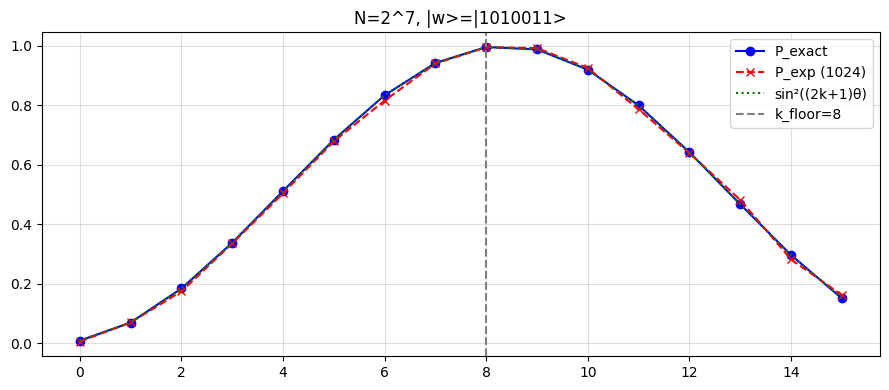


Доля запусков, где k_эксп = k_теор
 shots | совпало/20 |   доля
    16 |   10/20    |   0.50
    64 |   19/20    |   0.95
   256 |   20/20    |   1.00
  1024 |   20/20    |   1.00


In [9]:
print("ЗАДАНИЕ 5.|1010011>")

n5, m5 = 7, "1010011"
N5 = 2**n5
theta5 = asin(1/np.sqrt(N5))
k_round = round(pi/4*np.sqrt(N5))
k_floor = floor(pi/4*np.sqrt(N5))
oracle5 = build_oracle(n5, m5)
diffuser5 = build_diffuser(n5)

P_ex5, P_exp5 = [], []
for k in range(16):
    qc = QuantumCircuit(n5, n5); qc.h(range(n5))
    for _ in range(k):
        qc.compose(oracle5, inplace=True); qc.compose(diffuser5, inplace=True)
    sv = Statevector(qc)
    P_ex5.append(float(sv.probabilities()[int(m5, 2)]))
    qc.measure(range(n5), range(n5))
    P_exp5.append(sim.run(qc, shots=1024).result().get_counts().get(m5,0)/1024)

th5 = [sin((2*k+1)*theta5)**2 for k in range(16)]
print(f"5 N=128: round={k_round} P={th5[k_round]:.4f} | "
      f"floor={k_floor} P={th5[k_floor]:.4f} | "
      f"факт.max k={int(np.argmax(th5))}")
print(f"5 k_exact={int(np.argmax(P_ex5))}, P_max={max(P_ex5):.4f}")
print(f"5 k_exp ={int(np.argmax(P_exp5))}, P_max={max(P_exp5):.4f}")

print(f"{'величина':>26} | {'значение':>10}")
print(f"{'k_round = round(π/4·√N)':>26} | {k_round:>10}")
print(f"{'k_floor = floor(π/4·√N)':>26} | {k_floor:>10}")
print(f"{'k_теор (argmax sin²)':>26} | {int(np.argmax(th5)):>10}")
print(f"{'k_точн (argmax P_exact)':>26} | {int(np.argmax(P_ex5)):>10}")
print(f"{'k_эксп (argmax P_exp)':>26} | {int(np.argmax(P_exp5)):>10}")
print(f"{'max P_точн':>26} | {max(P_ex5):>10.4f}")
print(f"{'max P_эксп':>26} | {max(P_exp5):>10.4f}")

plt.figure(figsize=(9,4))
plt.plot(range(16), P_ex5, 'b-o', label='P_exact')
plt.plot(range(16), P_exp5, 'r--x', label='P_exp (1024)')
plt.plot(range(16), th5, 'g:', label='sin²((2k+1)θ)')
plt.axvline(k_floor, color='gray', ls='--', label=f'k_floor={k_floor}')
plt.title('N=2^7, |w>=|1010011>'); plt.legend(); plt.grid(alpha=0.4)
plt.tight_layout(); plt.show()

print("\nДоля запусков, где k_эксп = k_теор")
print(f"{'shots':>6} | {'совпало/20':>10} | {'доля':>6}")
for shots in (16,64,256,1024):
    hits = 0
    for seed in range(20):
        s_sim = AerSimulator(seed_simulator=seed)
        P_seed = []
        for k in range(16):
            qc = QuantumCircuit(n5, n5); qc.h(range(n5))
            for _ in range(k):
                qc.compose(oracle5, inplace=True); qc.compose(diffuser5, inplace=True)
            qc.measure(range(n5), range(n5))
            P_seed.append(s_sim.run(qc, shots=shots).result().get_counts().get(m5,0)/shots)
        if int(np.argmax(P_seed)) == int(np.argmax(th5)): hits += 1
    print(f"{shots:>6} | {hits:>4}/20    | {hits/20:>6.2f}")

Теоретический и экспериментальный оптимум
argmax точной P(k) : 8 (P = 0.995620)
round(π/4·√N) : 9 (P = 0.987779)
floor(π/4·√N) : 8 (P = 0.995620)
argmax экспериментальной P(k) : 8 (P = 0.995117)

P(8) = 0.995620, P(9) = 0.987779, ΔP = 0.007841
σ разности при 1024 shots: 0.004006; ΔP/σ = 1.96
  shots для надёжности 95%: 1027
  shots для надёжности 99.7%: 2405

Устойчивость оценки оптимума (20 запусков)
 shots | уникальный max при k=8 | доля ничьих
---------------------------------------------
    16 |                   0.10 |        0.90
    64 |                   0.50 |        0.50
   256 |                   0.90 |        0.10
  1024 |                   1.00 |        0.00


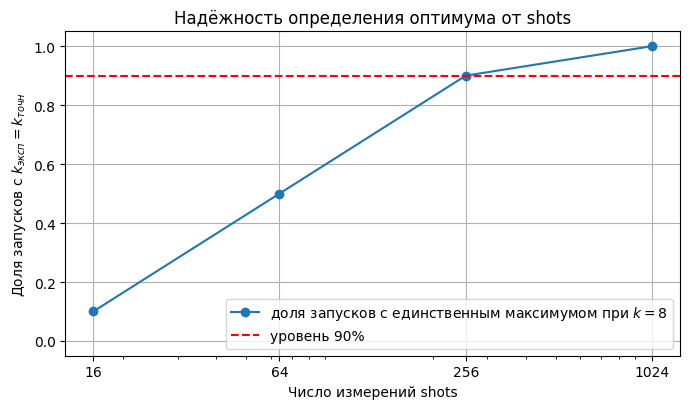

Минимальное число shots с долей ≥ 90%: 256


In [10]:
print("Теоретический и экспериментальный оптимум")

k_exact5 = int(np.argmax(P_ex5))
k_round5 = round(pi / 4 * np.sqrt(N5))
k_floor5 = floor(pi / 4 * np.sqrt(N5))
k_exp5 = int(np.argmax(P_exp5))

print(f"argmax точной P(k) : {k_exact5} (P = {P_ex5[k_exact5]:.6f})")
print(f"round(π/4·√N) : {k_round5} (P = {P_ex5[k_round5]:.6f})")
print(f"floor(π/4·√N) : {k_floor5} (P = {P_ex5[k_floor5]:.6f})")
print(f"argmax экспериментальной P(k) : {k_exp5} (P = {P_exp5[k_exp5]:.6f})")

k_a, k_b = k_floor5, k_floor5 + 1
pa, pb = P_ex5[k_a], P_ex5[k_b]
dP = abs(pa - pb)
var_sum = pa * (1 - pa) + pb * (1 - pb)
sigma_diff = np.sqrt(var_sum / 1024)

print(f"\nP({k_a}) = {pa:.6f}, P({k_b}) = {pb:.6f}, ΔP = {dP:.6f}")
print(f"σ разности при 1024 shots: {sigma_diff:.6f}; ΔP/σ = {dP / sigma_diff:.2f}")

if dP > 0:
    for z, label in [(1.96, '95%'), (3.0, '99.7%')]:
        need = (z * np.sqrt(var_sum) / dP) ** 2
        print(f"  shots для надёжности {label}: {need:.0f}")
else:
    print("  ΔP = 0 - соседние k неразличимы по вероятности")

print("\nУстойчивость оценки оптимума (20 запусков)")

SHOTS_GRID = [16, 64, 256, 1024]
fractions = []
tie_fractions = []

for shots in SHOTS_GRID:
    good = 0
    ties = 0
    for seed in range(20):
        P_seed = []
        for k in range(16):
            qc = QuantumCircuit(n5, n5); qc.h(range(n5))
            for _ in range(k):
                qc.compose(oracle5, inplace=True)
                qc.compose(diffuser5, inplace=True)
            qc.measure(range(n5), range(n5))
            s_sim = AerSimulator(seed_simulator=seed * 100 + k)
            P_seed.append(s_sim.run(qc, shots=shots).result().get_counts().get(m5, 0) / shots)

        best = max(P_seed)
        winners = [k for k in range(16) if P_seed[k] == best]
        if len(winners) > 1:
            ties += 1
        if winners == [k_exact5]:
            good += 1
    fractions.append(good / 20)
    tie_fractions.append(ties / 20)

hdr = f"{'shots':>6} | {'уникальный max при k=' + str(k_exact5):>22} | {'доля ничьих':>11}"
print(hdr)
print("-" * len(hdr))
for shots, f, t in zip(SHOTS_GRID, fractions, tie_fractions):
    print(f"{shots:>6} | {f:>22.2f} | {t:>11.2f}")

plt.figure(figsize=(7, 4.2))
plt.plot(SHOTS_GRID, fractions, 'o-',
         label=f'доля запусков с единственным максимумом при $k={k_exact5}$')
plt.axhline(0.9, color='red', linestyle='--', label='уровень 90%')
plt.xscale('log')
plt.xlabel('Число измерений shots')
plt.ylabel(r'Доля запусков с $k_{эксп} = k_{точн}$')
plt.title('Надёжность определения оптимума от shots')
plt.xticks(SHOTS_GRID, [str(s) for s in SHOTS_GRID])
plt.ylim(-0.05, 1.05)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

ok_shots = [s for s, f in zip(SHOTS_GRID, fractions) if f >= 0.9]
print(f"Минимальное число shots с долей ≥ 90%: {min(ok_shots) if ok_shots else 'не достигнуто'}")

Задание 6. Несколько решений М при N=64.

ЗАДАНИЕ 6. Гровер при M решениях, N=64

Гровер при M решениях, N=64
  M | k_теор | k_1макс |  P_1макс |  k_глоб
  1 |      6 |       6 |   0.9966 |       6
  2 |      4 |       4 |   0.9992 |       4
  3 |      3 |       3 |   0.9981 |       3
  4 |      3 |       3 |   0.9613 |      15
  8 |      2 |       2 |   0.9453 |       6


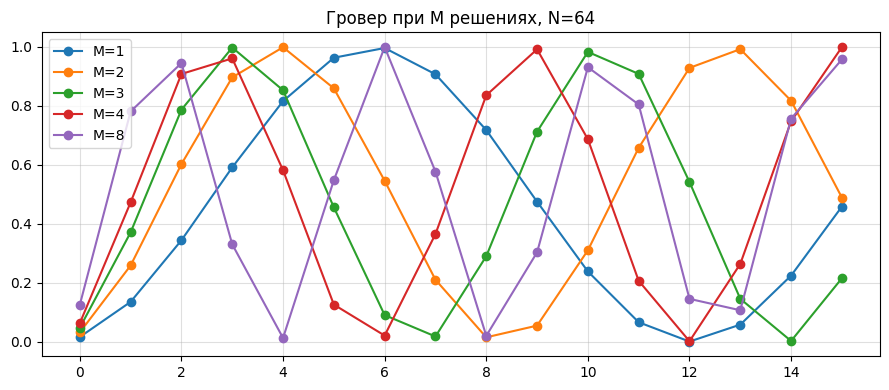


Большие M (N=64)
  M |  k_опт |   P_max |    P(0)
 32 |      0 |  0.5000 |  0.5000
 48 |      0 |  0.7500 |  0.7500


In [11]:
print("ЗАДАНИЕ 6. Гровер при M решениях, N=64")
n6, N6 = 6, 64
np.random.seed(42)

def run_multi(ms_strings, k_max=16):
    oracle = QuantumCircuit(n6)
    for ms in ms_strings:
        oracle.compose(build_oracle(n6, ms), inplace=True)
    diffuser = build_diffuser(n6)
    P = []
    for k in range(k_max):
        qc = QuantumCircuit(n6); qc.h(range(n6))
        for _ in range(k):
            qc.compose(oracle, inplace=True); qc.compose(diffuser, inplace=True)
        sv = Statevector(qc)
        P.append(sum(float(sv.probabilities()[int(ms, 2)]) for ms in ms_strings))
    return P

print("\nГровер при M решениях, N=64")
print(f"{'M':>3} | {'k_теор':>6} | {'k_1макс':>7} | {'P_1макс':>8} | {'k_глоб':>7}")
plt.figure(figsize=(9,4))
for M in (1,2,3,4,8):
    idxs = sorted(np.random.choice(range(N6), M, replace=False))
    ms = [format(x, f'0{n6}b') for x in idxs]
    P = run_multi(ms)
    first = next(k for k in range(1,len(P)-1) if P[k]>P[k-1] and P[k]>P[k+1])
    kth = floor(pi/4*np.sqrt(N6/M))
    print(f"{M:>3} | {kth:>6} | {first:>7} | {P[first]:>8.4f} | {int(np.argmax(P)):>7}")
    plt.plot(range(16), P, 'o-', label=f'M={M}')
plt.title('Гровер при M решениях, N=64')
plt.legend(); plt.grid(alpha=0.4); plt.tight_layout(); plt.show()

print("\nБольшие M (N=64)")
print(f"{'M':>3} | {'k_опт':>6} | {'P_max':>7} | {'P(0)':>7}")
np.random.seed(42)
for M in (N6//2, 3*N6//4):
    idxs = sorted(np.random.choice(range(N6), M, replace=False))
    ms = [format(x, f'0{n6}b') for x in idxs]
    P = run_multi(ms)
    print(f"{M:>3} | {int(np.argmax(P)):>6} | {max(P):>7.4f} | {P[0]:>7.4f}")

Задание 7. Вариант 1 - N=32, ∣w⟩=∣01010⟩.

ЗАДАНИЕ 7. Вариант 1: N=32, |w>=|01010>
7 N=32, k_opt=4
7 k_exact=4, P_max=0.9992
7 k_exp =4, P_max=0.9990
7 Топ-3 при k=4: [('01010', 1023), ('01000', 1)]

Вариант 1: N=2^5, |w>=|01010>
                  величина |   значение
                         N |         32
    k_теор = floor(π/4·√N) |          4
   k_точн (argmax P_exact) |          4
     k_эксп (argmax P_exp) |          4
                max P_точн |     0.9992
                max P_эксп |     0.9990


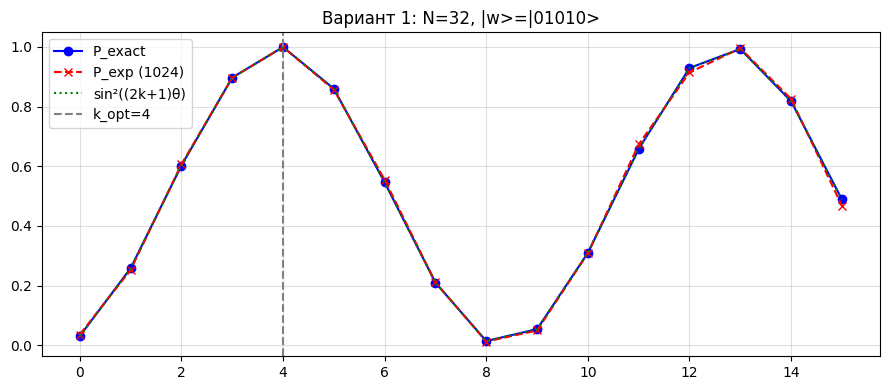


Влияние двухкубитного шума (p1=0.001)
    p2 |  k_max |   P_max |  P(k_opt)
 0.000 |      4 |  0.9992 |    0.9992


/usr/local/lib/python3.13/dist-packages/qiskit/transpiler/preset_passmanagers/generate_preset_pass_manager.py:242: UserWarning: Providing `coupling_map` and/or `basis_gates` along with `backend` is not recommended, as this will invalidate the backend's gate durations and error rates.
  common_options = _parse_common_options(


 0.005 |      3 |  0.3750 |    0.3281
 0.020 |      1 |  0.0918 |    0.0410


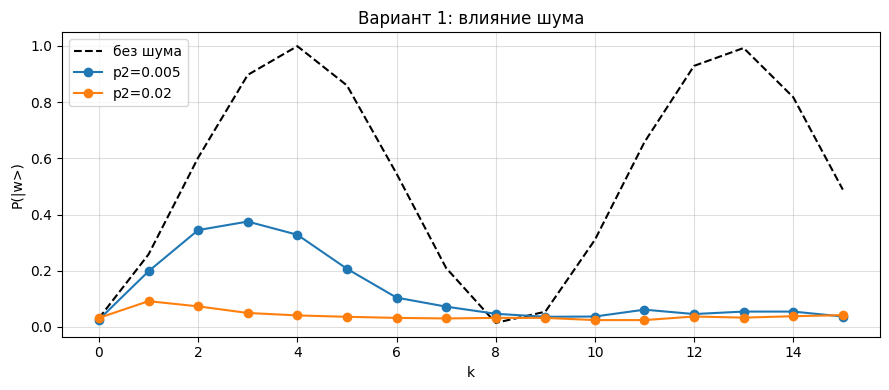

In [12]:
print("ЗАДАНИЕ 7. Вариант 1: N=32, |w>=|01010>")

n7, m7 = 5, "01010"
N7 = 2**n7
theta7 = asin(1/np.sqrt(N7))
k_opt7 = floor(pi/4*np.sqrt(N7))
print(f"7 N={N7}, k_opt={k_opt7}")
oracle7 = build_oracle(n7, m7)
diffuser7 = build_diffuser(n7)

P_ex7, P_exp7 = [], []
counts_opt7 = None
for k in range(16):
    qc = QuantumCircuit(n7, n7); qc.h(range(n7))
    for _ in range(k):
        qc.compose(oracle7, inplace=True); qc.compose(diffuser7, inplace=True)
    sv = Statevector(qc)
    P_ex7.append(sv.probabilities_dict().get(m7[::-1], 0))
    qc.measure(range(n7), range(n7))
    c = sim.run(qc, shots=1024).result().get_counts()
    P_exp7.append(c.get(m7,0)/1024)
    if k == k_opt7: counts_opt7 = c

th7 = [sin((2*k+1)*theta7)**2 for k in range(16)]
print(f"7 k_exact={int(np.argmax(P_ex7))}, P_max={max(P_ex7):.4f}")
print(f"7 k_exp ={int(np.argmax(P_exp7))}, P_max={max(P_exp7):.4f}")
print(f"7 Топ-3 при k={k_opt7}: {Counter(counts_opt7).most_common(3)}")

print("\nВариант 1: N=2^5, |w>=|01010>")
print(f"{'величина':>26} | {'значение':>10}")
print(f"{'N':>26} | {N7:>10}")
print(f"{'k_теор = floor(π/4·√N)':>26} | {k_opt7:>10}")
print(f"{'k_точн (argmax P_exact)':>26} | {int(np.argmax(P_ex7)):>10}")
print(f"{'k_эксп (argmax P_exp)':>26} | {int(np.argmax(P_exp7)):>10}")
print(f"{'max P_точн':>26} | {max(P_ex7):>10.4f}")
print(f"{'max P_эксп':>26} | {max(P_exp7):>10.4f}")

plt.figure(figsize=(9,4))
plt.plot(range(16), P_ex7, 'b-o', label='P_exact')
plt.plot(range(16), P_exp7, 'r--x', label='P_exp (1024)')
plt.plot(range(16), th7, 'g:', label='sin²((2k+1)θ)')
plt.axvline(k_opt7, color='gray', ls='--', label=f'k_opt={k_opt7}')
plt.title('Вариант 1: N=32, |w>=|01010>')
plt.legend(); plt.grid(alpha=0.4); plt.tight_layout(); plt.show()

print("\nВлияние двухкубитного шума (p1=0.001)")
print(f"{'p2':>6} | {'k_max':>6} | {'P_max':>7} | {'P(k_opt)':>9}")
print(f"{0.0:>6.3f} | {int(np.argmax(P_ex7)):>6} | {max(P_ex7):>7.4f} | "
      f"{P_ex7[k_opt7]:>9.4f}")

plt.figure(figsize=(9,4))
plt.plot(range(16), P_ex7, 'k--', label='без шума')
for p2 in (0.005, 0.02):
    nm = NoiseModel()
    nm.add_all_qubit_quantum_error(depolarizing_error(p2,2), ['cx'])
    P_noisy = []
    for k in range(16):
        qc = QuantumCircuit(n7, n7); qc.h(range(n7))
        for _ in range(k):
            qc.compose(oracle7, inplace=True); qc.compose(diffuser7, inplace=True)
        qc.measure(range(n7), range(n7))
        tqc = transpile(qc, sim, basis_gates=['u','cx'])
        c = sim.run(tqc, shots=1024, noise_model=nm).result().get_counts()
        P_noisy.append(c.get(m7,0)/1024)
    print(f"{p2:>6.3f} | {int(np.argmax(P_noisy)):>6} | {max(P_noisy):>7.4f} | "
          f"{P_noisy[k_opt7]:>9.4f}")
    plt.plot(range(16), P_noisy, 'o-', label=f'p2={p2}')
plt.title('Вариант 1: влияние шума')
plt.xlabel('k'); plt.ylabel('P(|w>)'); plt.legend(); plt.grid(alpha=0.4)
plt.tight_layout(); plt.show()